# Feature Selection

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_disease.csv")

X = df.drop(columns=['target'])  
y = df['target']  

## 1. Use Feature Importance (Random Forest / XGBoost feature importance scores) to rank variables. 

### Random Forest

In [5]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

rf = RandomForestClassifier()
rf.fit(X, y)

importances = rf.feature_importances_

feature_ranking = pd.Series(importances, index=X.columns).sort_values(ascending=False)

print(feature_ranking)

plt.figure(figsize=(10, 6))
feature_ranking.plot(kind='bar')
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'matplotlib.backends.registry'

### **Comment on Random Forest feature importance:** we can see the ranking that is produced and will compare it to XGBoost

### XGBoost

cp_4.0         0.271299
thal_7         0.181887
ca             0.110182
sex_1.0        0.056738
oldpeak        0.050313
slope_2.0      0.044287
thal_6         0.041938
exang_1.0      0.040501
cp_3.0         0.032451
age            0.031482
trestbps       0.028007
chol           0.026590
thalach        0.025557
cp_2.0         0.025177
restecg_2.0    0.020463
fbs_1.0        0.013128
restecg_1.0    0.000000
slope_3.0      0.000000
dtype: float32


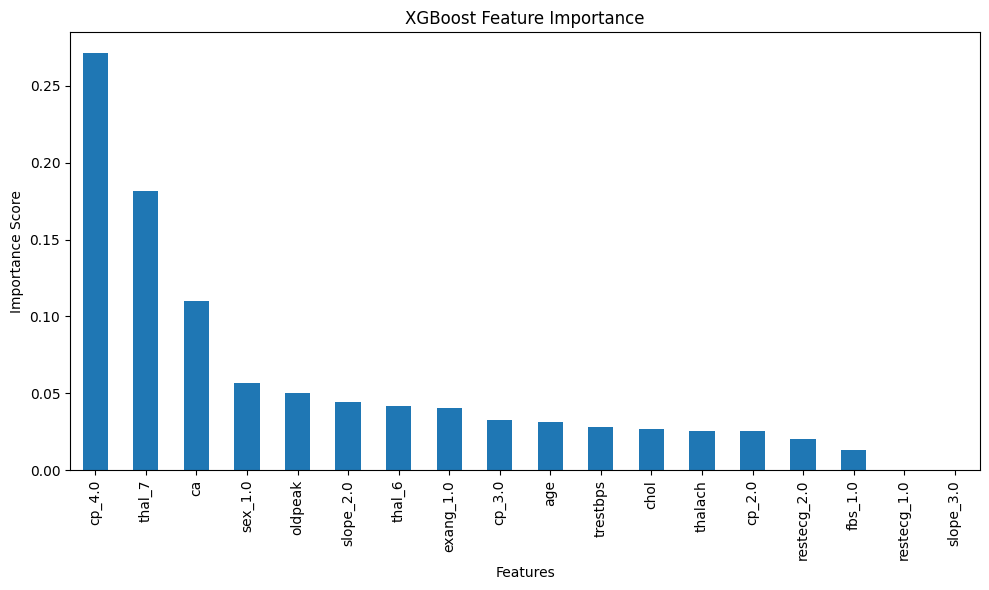

In [49]:
from xgboost import XGBClassifier 

xgb = XGBClassifier(use_label_encoder=False)

xgb.fit(X, y)

importances = xgb.feature_importances_

feature_ranking = pd.Series(importances, index=X.columns).sort_values(ascending=False)

print(feature_ranking)

plt.figure(figsize=(10, 6))
feature_ranking.plot(kind='bar')
plt.title("XGBoost Feature Importance")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

### **Comparing Random Forest with XGBoost:**
#### There are common features in the top 5 but also XGBoost importance values are higher than random forest and introduced features like sex_1 to the top 5

## 2. Apply Recursive Feature Elimination (RFE) to select the best predictors. 

Optimal number of features: 6
Selected features: Index(['ca', 'sex_1.0', 'cp_4.0', 'exang_1.0', 'slope_2.0', 'thal_7'], dtype='object')


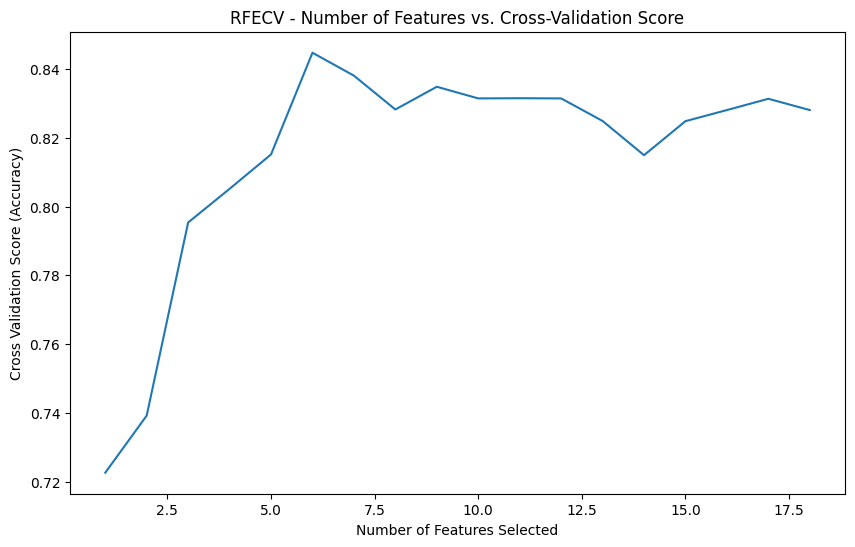

In [50]:
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC


estimator = LogisticRegression()
cv = StratifiedKFold(5)

rfecv = RFECV(estimator=estimator, step=1, cv=cv, scoring='accuracy')
rfecv.fit(X, y)

print("Optimal number of features:", rfecv.n_features_)
print("Selected features:", X.columns[rfecv.support_])

plt.figure(figsize=(10, 6))
plt.title('RFECV - Number of Features vs. Cross-Validation Score')
plt.xlabel('Number of Features Selected')
plt.ylabel('Cross Validation Score (Accuracy)')
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
plt.show()


RFE using XGBoost: ['ca', 'cp_4.0', 'thal_7'] > 0.82 <br>
RFE using Random Forest: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex_1.0',
       'cp_2.0', 'cp_3.0', 'cp_4.0', 'fbs_1.0', 'restecg_2.0', 'exang_1.0',
       'slope_2.0', 'thal_7']  = 0.82<br>
RFE using logistic regression: ['ca', 'sex_1.0', 'cp_4.0', 'exang_1.0', 'slope_2.0', 'thal_7'] > 85<br>
RFE using SVM: ['oldpeak', 'ca', 'sex_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'fbs_1.0',
       'restecg_2.0', 'exang_1.0', 'slope_2.0', 'thal_6', 'thal_7'] -> 83<br>

ca, cp_4.0,thal_7 are common between all<br>
sex_1.0, exang_1.0, slope_2.0 are common between the Random Forest, logistic regression and SVM<br>
<br>
logistic regression has the highest accuracy and has 6 features


## 3. Use Chi-Square Test to check feature significance. 

### **Note:** I used MinMaxScaler as Chi-Square test requires all input features to be non-negative

        Feature  Chi2 Score       P-Value
17       thal_7   42.958360  5.591745e-11
9        cp_4.0   42.410097  7.400700e-11
13    exang_1.0   38.052613  6.886243e-10
5            ca   27.832905  1.322575e-07
8        cp_3.0   21.551109  3.445235e-06
14    slope_2.0   20.624160  5.588639e-06
4       oldpeak   16.817971  4.114184e-05
7        cp_2.0   15.646367  7.635913e-05
6       sex_1.0    7.432845  6.404399e-03
12  restecg_2.0    3.987845  4.582964e-02
16       thal_6    3.889888  4.857765e-02
3       thalach    2.670638  1.022151e-01
11  restecg_1.0    1.366567  2.424027e-01
15    slope_3.0    1.073891  3.000681e-01
0           age    1.005896  3.158880e-01
1      trestbps    0.619899  4.310847e-01
2          chol    0.251667  6.159039e-01
10      fbs_1.0    0.164669  6.848935e-01
['thal_7', 'cp_4.0', 'exang_1.0', 'ca', 'cp_3.0', 'slope_2.0', 'oldpeak', 'cp_2.0', 'sex_1.0', 'restecg_2.0', 'thal_6']


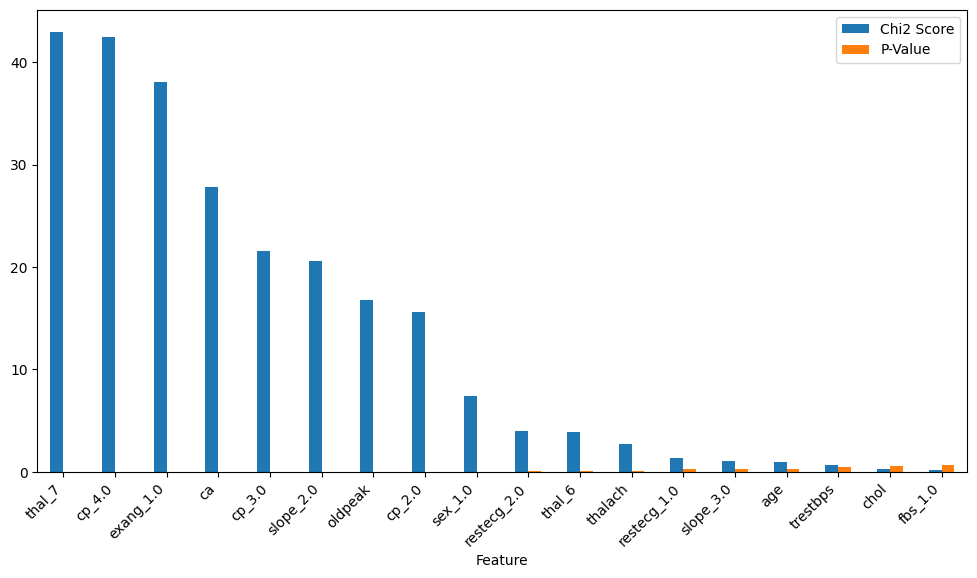

In [51]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler


scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)


selector = SelectKBest(score_func=chi2, k='all')
selector.fit(X_scaled, y)


chi2_results = pd.DataFrame({
    'Feature': X.columns,
    'Chi2 Score': selector.scores_,
    'P-Value': selector.pvalues_
}).sort_values(by='Chi2 Score', ascending=False)

significant_features = chi2_results[chi2_results['P-Value'] < 0.05]['Feature'].tolist()


print(chi2_results)
print(significant_features)
ax =chi2_results.plot(kind="bar", x='Feature', figsize=(12, 6))
plt.xticks(rotation=45, ha='right')
plt.show()

## 4. Select only the most relevant features for modeling. 

[ca, thalach, oldpeak, cp_4.0, age, thal_7, chol, trestbps, exang_1.0, slope_2.0, sex_1.0, cp_3.0, restecg_2.0] using random forest feature importance<br><br>
['cp_4.0', 'thal_7', 'ca', 'sex_1.0', 'oldpeak', 'slope_2.0', 'thal_6', 'exang_1.0', 'cp_3.0', 'age', 'trestbps', 'chol', 'thalach', 'cp_2.0', 'restecg_2.0'] using XGBoost feature importance <br><br>
['ca', 'sex_1.0', 'cp_4.0', 'exang_1.0', 'slope_2.0', 'thal_7'] from RFE using Logistic regression<br><br>
[ 'ca', 'sex_1.0','cp_4.0', 'exang_1.0', 'slope_2.0', 'thal_7',  'cp_3.0',  'oldpeak', 'cp_2.0',  'restecg_2.0', 'thal_6'] from Chi Square test<br><br>


selecting the common ones: <br>
['ca', 'cp_4.0', 'thal_7', 'exang_1.0','slope_2.0', 'sex_1.0', 'oldpeak', 'cp_3.0', 'restecg_2.0']<br><br>

I have chosen 9 features that has been repeated atleast 3 times between all these types of feature selecting

In [52]:
import os

X_final = X[[
    'ca', 'cp_4.0', 'thal_7', 'exang_1.0', 
    'slope_2.0', 'sex_1.0', 'oldpeak', 
    'cp_3.0', 'restecg_2.0'
]]


# Combine features and target
df_final = pd.concat([X_final, y], axis=1)

df_final = df_final.rename(columns={'num': 'target'})

folder_path = "../data"
file_name = "heart_disease_feature_selected.csv"
full_path = os.path.join(folder_path, file_name)

df_final.to_csv(full_path, index=False)

df_final

,ca,cp_4.0,thal_7,exang_1.0,slope_2.0,sex_1.0,oldpeak,cp_3.0,restecg_2.0,target
0,-0.719117,False,False,False,False,True,1.087338,False,True,0
1,2.500969,True,False,True,True,True,0.397182,False,True,1
2,1.427607,True,True,True,True,True,1.346147,False,True,1
3,-0.719117,False,False,False,False,True,2.122573,True,False,0
4,-0.719117,False,False,False,False,False,0.310912,False,True,0
...,...,...,...,...,...,...,...,...,...,...
298,-0.719117,False,True,False,True,True,0.138373,False,False,1
299,1.427607,True,True,False,True,True,2.036303,False,False,1
300,0.354245,True,True,True,True,True,0.138373,False,False,1
301,0.354245,False,False,False,True,False,-0.896862,False,True,1
